# Support Ticket Router: Fine-tune Qwen3-1.7B-Base with LLaMA Board (end to end)

The Gen Academy's course notebook *Finetune_Support_Ticket_Classifier_Qwen3*
([original](original/Finetune_Support_Ticket_Classifier_Qwen3.ipynb)), completed for this project.

* **Runs on Google Colab (T4) or locally** (Apple-silicon `mps` / CUDA / CPU). On Colab it clones this
  repository, which also contains the trained LoRA adapter, so you can evaluate without retraining.
* **The outputs in this copy come from a local run on an Apple M2 (16 GB).** The training itself was
  done through LLaMA Board (see [`docs/PHASE3_TRAINING.md`](../docs/PHASE3_TRAINING.md)).
* The course code is kept as close to the original as possible. Changes are marked `# FIX:` or `# CHANGED:`.
  The important one: `classification_report(..., target_names=...)` now also gets `labels=`. Without it,
  sklearn sorts the classes alphabetically and the row names don't match the numbers.

## The scenario

An IT helpdesk routes every ticket by hand. A small fine-tuned model reads each ticket first and returns
exactly one of seven queue labels (`Active Directory`, `Computer-Services`, `EOL`, `Fileservice`, `O365`,
`Software`, `Support general`). It never writes a reply. It's cheaper and faster than a frontier model, and
more robust than keyword rules.

## Setup (paths, dependencies)

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/senthilkumarpackiyam/SupportTicketRouter.git"
LLAMA_FACTORY_COMMIT = "f6355ab6a426eedb800742ecf61896f7bff95ebb"  # pinned (v0.9.6.dev0)

if IN_COLAB:
    PROJECT_DIR = Path("/content/SupportTicketRouter")
    LF_DIR      = Path("/content/LLaMA-Factory")
    if not PROJECT_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    if not LF_DIR.exists():
        subprocess.run(["git", "clone", "https://github.com/hiyouga/LLaMA-Factory.git", str(LF_DIR)], check=True)
        subprocess.run(["git", "-C", str(LF_DIR), "checkout", LLAMA_FACTORY_COMMIT], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", f"{LF_DIR}[torch,bitsandbytes]"], check=True)
else:
    # local: run from the repo root or from notebooks/ after ./setup.sh
    PROJECT_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
    LF_DIR      = PROJECT_DIR / "LLaMA-Factory"

NB_OUT = PROJECT_DIR / "results" / "notebook_run"   # plots + val split written by this notebook
NB_OUT.mkdir(parents=True, exist_ok=True)
print("Colab:", IN_COLAB, "| project:", PROJECT_DIR, "| LLaMA-Factory:", LF_DIR)

Colab: False | project: /Users/senthilkumarpackiyam/Documents/GEN_ACADEMY/week5 | LLaMA-Factory: /Users/senthilkumarpackiyam/Documents/GEN_ACADEMY/week5/LLaMA-Factory


### Check GPU environment

In [2]:
import torch
# CHANGED: the course asserts CUDA; this also accepts Apple-silicon GPUs (mps)
if torch.cuda.is_available():
    print("CUDA GPU:", torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    print("Apple-silicon GPU (mps)")
else:
    print("No GPU found: training via LLaMA Board needs one (inference below still runs on CPU, slowly)")

Apple-silicon GPU (mps)


## Prepare Support Ticket Dataset

Same as the course cell: stratified 80/20 split (seed 42), training split to **ShareGPT JSON**
(`LLaMA-Factory/data/TRAIN.json`), registered as `support_tickets` in `dataset_info.json`.
CHANGED: the CSV is read from the repository instead of a browser upload.

In [3]:
import json
import pandas as pd
from sklearn.model_selection import train_test_split

LLAMA_DATA_DIR  = LF_DIR / "data"
TRAIN_JSON_PATH = LLAMA_DATA_DIR / "TRAIN.json"
DATASET_INFO    = LLAMA_DATA_DIR / "dataset_info.json"
CSV_PATH        = PROJECT_DIR / "data" / "raw" / "support_tickets.csv"   # CHANGED: no upload needed

LABEL2ID = {
    "Support general":   0,
    "Fileservice":       1,
    "O365":              2,
    "EOL":               3,
    "Software":          4,
    "Active Directory":  5,
    "Computer-Services": 6,
}

SYSTEM_PROMPT = (
    "You are an IT helpdesk ticket routing assistant. "
    "Given a support ticket, respond with exactly one of the following categories: "
    "Support general, Fileservice, O365, EOL, Software, Active Directory, Computer-Services."
)

df = pd.read_csv(CSV_PATH).rename(columns={"category_truth": "label"})
df = df[df["label"].isin(LABEL2ID)].sample(frac=1, random_state=42).reset_index(drop=True)
print(f"Loaded {len(df):,} rows")

df_train, df_val = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=42)
df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
print(f"Train: {len(df_train):,} rows | Val (held-out): {len(df_val):,} rows")

sharegpt_records = [
    {"messages": [
        {"role": "system",    "content": SYSTEM_PROMPT},
        {"role": "user",      "content": f"Support Ticket: {row['text']}"},
        {"role": "assistant", "content": row["label"]},
    ]}
    for _, row in df_train.iterrows()
]
with open(TRAIN_JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(sharegpt_records, f, indent=2, ensure_ascii=False)

with open(DATASET_INFO, "r", encoding="utf-8") as f:
    info = json.load(f)
info["support_tickets"] = {
    "file_name": "TRAIN.json", "formatting": "sharegpt", "columns": {"messages": "messages"},
    "tags": {"role_tag": "role", "content_tag": "content", "user_tag": "user",
             "assistant_tag": "assistant", "system_tag": "system"},
}
with open(DATASET_INFO, "w", encoding="utf-8") as f:
    json.dump(info, f, indent=2, ensure_ascii=False)

VAL_CSV = NB_OUT / "val_split.csv"
df_val.to_csv(VAL_CSV, index=False)
print(f"Written {len(sharegpt_records):,} records -> {TRAIN_JSON_PATH}; val split -> {VAL_CSV}")

# sanity: identical to the split used by the project's scripts
ref = pd.read_csv(PROJECT_DIR / "data" / "processed" / "val_split.csv")
print("Same validation tickets as data/processed/val_split.csv:", ref["text"].tolist() == df_val["text"].tolist())

Loaded 585 rows
Train: 468 rows | Val (held-out): 117 rows
Written 468 records -> /Users/senthilkumarpackiyam/Documents/GEN_ACADEMY/week5/LLaMA-Factory/data/TRAIN.json; val split -> /Users/senthilkumarpackiyam/Documents/GEN_ACADEMY/week5/results/notebook_run/val_split.csv
Same validation tickets as data/processed/val_split.csv: True


## Fine-tune model via LLaMA Board

On Colab, set `TRAIN_NOW = True`. LLaMA Board then opens with a public link: choose `Qwen3-1.7B-Base`,
dataset `support_tickets`, finetuning method `lora`, keep the defaults, and click **Start**. Stop the cell
when training has finished, and put the Output Dir into `ADAPTER_DIR` below.

Locally, this project already trained through LLaMA Board (driven by
[`scripts/llamaboard_train.py`](../scripts/llamaboard_train.py), 69 min on the M2), and the resulting
adapter is committed in [`adapters/`](../adapters/qwen3-1.7b-support-router-lora/).

In [4]:
TRAIN_NOW = False   # True on Colab to train your own adapter (course step)

if TRAIN_NOW:
    os.chdir(LF_DIR)
    get_ipython().system("GRADIO_SHARE=1 llamafactory-cli webui")
else:
    print("Skipping training: using the adapter trained via LLaMA Board and committed to this repo.")

Skipping training: using the adapter trained via LLaMA Board and committed to this repo.


## Review Training: Loss Curve

The loss should fall steadily and then level off.

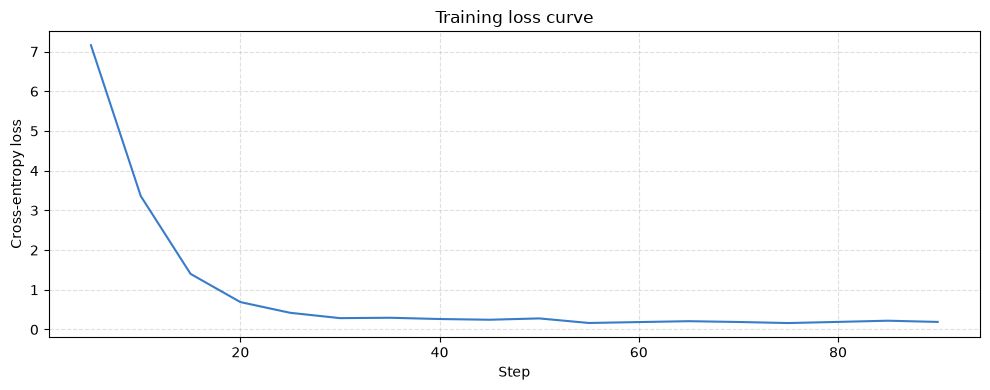

Starting loss : 7.1595
Final loss    : 0.1907
Total drop    : 6.9688

Loss is low — model has likely converged well.


In [5]:
import json, matplotlib.pyplot as plt
from pathlib import Path

# CHANGED: defaults to the adapter committed in this repo; on Colab after TRAIN_NOW use
# LF_DIR / "saves/Qwen3-1.7B-Base/lora/train_XXXX-XX-XX-XX-XX-XX"
ADAPTER_DIR     = str(PROJECT_DIR / "adapters" / "qwen3-1.7b-support-router-lora")
# CHANGED: ".nosync" keeps the 3.4 GB merged model out of iCloud Drive on a Mac
MERGED_DIR      = "/content/qwen3_merged" if IN_COLAB else str(PROJECT_DIR / "models.nosync" / "qwen3-1.7b-support-router-merged")
BASE_MODEL_NAME = "Qwen/Qwen3-1.7B-Base"

log_file = Path(ADAPTER_DIR) / "trainer_log.jsonl"
if not log_file.exists():
    raise FileNotFoundError(f"trainer_log.jsonl not found in {ADAPTER_DIR!r}")

records = [json.loads(l) for l in log_file.read_text().splitlines() if l.strip()]
steps   = [r["current_steps"] for r in records if r.get("loss") is not None]
losses  = [r["loss"]          for r in records if r.get("loss") is not None]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(steps, losses, linewidth=1.5, color="#1565C0", alpha=0.85)
ax.set_xlabel("Step")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("Training loss curve")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(NB_OUT / "training_curve.png", dpi=120)
plt.show()

total_drop = losses[0] - losses[-1]
print(f"Starting loss : {losses[0]:.4f}")
print(f"Final loss    : {losses[-1]:.4f}")
print(f"Total drop    : {total_drop:.4f}")
print()
if losses[-1] < 0.5:
    print("Loss is low — model has likely converged well.")
elif losses[-1] < 1.2:
    print("Loss is moderate — model has learned but may benefit from more epochs.")
else:
    print("Loss is still high — consider more epochs, a lower learning rate, or checking the data format.")

## Merge Adapter Weights, Measure Baseline & Prepare for Inference

1. Load the base model.
2. **Zero-shot baseline** on the validation split (A–G letter choice).
3. Attach the LoRA adapter, `merge_and_unload()`, save the standalone model.

The tokenizer is loaded **from the adapter folder**. LLaMA-Factory saved it with the chat template used
in training (LLaMA Board's `default`: `System: … Human: … Assistant:`).

In [6]:
import os, gc, json, torch, pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftConfig, get_peft_model
from peft.utils import set_peft_model_state_dict
import safetensors.torch as st

LABEL_TOKENS = [
    "Support general", "Fileservice", "O365", "EOL",
    "Software", "Active Directory", "Computer-Services",
]
CHOICES      = "ABCDEFG"
CHOICE2LABEL = {ch: lbl for ch, lbl in zip(CHOICES, LABEL_TOKENS)}

BASE_SYSTEM_PROMPT = (
    "You are an IT helpdesk ticket routing assistant. "
    "Classify the ticket by responding with ONLY a single letter — nothing else:\n"
    + "\n".join(f"{ch}) {lbl}" for ch, lbl in CHOICE2LABEL.items())
)

adapter_path = Path(ADAPTER_DIR)
if not (adapter_path / "adapter_config.json").exists():
    raise FileNotFoundError(f"No adapter_config.json in {ADAPTER_DIR!r}")
print(f"Adapter found: {ADAPTER_DIR}")

HAS_CUDA = torch.cuda.is_available()
HAS_MPS  = hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
DEVICE   = "cuda" if HAS_CUDA else ("mps" if HAS_MPS else "cpu")
dtype    = torch.float16 if DEVICE in ("cuda", "mps") else torch.float32
print(f"Device: {DEVICE}")

print("\nLoading base model...")
base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_NAME, dtype=dtype, device_map=DEVICE,   # CHANGED: torch_dtype -> dtype (transformers 5)
)
tok_src    = str(adapter_path) if (adapter_path / "tokenizer.json").exists() else BASE_MODEL_NAME
_tokenizer = AutoTokenizer.from_pretrained(tok_src)
base_model.eval()

_choice_ids = []
for ch in CHOICES:
    ids_plain  = _tokenizer.encode(ch,       add_special_tokens=False)
    ids_spaced = _tokenizer.encode(f" {ch}", add_special_tokens=False)
    _choice_ids.append(ids_spaced[0] if len(ids_spaced) == 1 else ids_plain[0])


def classify_base(ticket_text: str) -> str:
    messages = [
        {"role": "system", "content": BASE_SYSTEM_PROMPT},
        {"role": "user",   "content": f"Support Ticket: {ticket_text}"},
    ]
    prompt = _tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = _tokenizer(prompt, return_tensors="pt").to(base_model.device)
    with torch.no_grad():
        out = base_model(input_ids=inputs["input_ids"])
    first_logits = out.logits[0, -1, :]
    choice_probs = torch.softmax(first_logits[_choice_ids], dim=-1).cpu().tolist()
    return CHOICE2LABEL[CHOICES[choice_probs.index(max(choice_probs))]]


df_val      = pd.read_csv(VAL_CSV)
y_true      = df_val["label"].tolist()
y_pred_base = []
for _, row in tqdm(df_val.iterrows(), total=len(df_val), desc="Baseline inference"):
    y_pred_base.append(classify_base(row["text"]))

from sklearn.metrics import classification_report
print("\n=== Baseline (no fine-tuning) ===")
# FIX: labels=LABEL_TOKENS so the row names match the numbers
print(classification_report(y_true, y_pred_base, labels=LABEL_TOKENS, target_names=LABEL_TOKENS, digits=3, zero_division=0))

print("Attaching LoRA adapter...")
peft_cfg   = PeftConfig.from_pretrained(str(adapter_path))
peft_model = get_peft_model(base_model, peft_cfg)
weights_file    = adapter_path / "adapter_model.safetensors"
adapter_weights = st.load_file(str(weights_file), device=DEVICE)
set_peft_model_state_dict(peft_model, adapter_weights)

print("Merging (this may take a while) ...")
_model = peft_model.merge_and_unload()
os.makedirs(MERGED_DIR, exist_ok=True)
_model.save_pretrained(MERGED_DIR)
_tokenizer.save_pretrained(MERGED_DIR)
stale = Path(MERGED_DIR) / "adapter_config.json"
if stale.exists():
    stale.unlink()
print(f"Saved → {MERGED_DIR}")

del peft_model, base_model, adapter_weights
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
_model.eval()
print("Model ready for inference.")

Adapter found: /Users/senthilkumarpackiyam/Documents/GEN_ACADEMY/week5/adapters/qwen3-1.7b-support-router-lora
Device: mps

Loading base model...


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Baseline inference:   0%|          | 0/117 [00:00<?, ?it/s]


=== Baseline (no fine-tuning) ===
                   precision    recall  f1-score   support

  Support general      0.248     0.933     0.392        30
      Fileservice      0.000     0.000     0.000        28
             O365      0.000     0.000     0.000        18
              EOL      1.000     0.083     0.154        12
         Software      0.000     0.000     0.000        12
 Active Directory      0.000     0.000     0.000         9
Computer-Services      0.000     0.000     0.000         8

         accuracy                          0.248       117
        macro avg      0.178     0.145     0.078       117
     weighted avg      0.166     0.248     0.116       117

Attaching LoRA adapter...


Merging (this may take a while) ...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved → /Users/senthilkumarpackiyam/Documents/GEN_ACADEMY/week5/models.nosync/qwen3-1.7b-support-router-merged
Model ready for inference.


## Define `classify()` and Smoke Test the Merged Model

Greedy decoding of up to 10 tokens, prefix match against the seven labels. Confidence is the softmax over
the labels' first tokens at the first generated position.

In [7]:
import torch

LABEL_TOKENS = [
    "Support general", "Fileservice", "O365", "EOL",
    "Software", "Active Directory", "Computer-Services",
]


def classify(ticket_text: str, compute_confidence: bool = True) -> tuple:
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user",   "content": f"Support Ticket: {ticket_text}"},
    ]
    prompt = _tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = _tokenizer(prompt, return_tensors="pt").to(_model.device)

    with torch.no_grad():
        out = _model.generate(
            **inputs, max_new_tokens=10, do_sample=False,
            output_scores=True, return_dict_in_generate=True,
            pad_token_id=_tokenizer.eos_token_id,
        )

    generated = _tokenizer.decode(out.sequences[0][inputs["input_ids"].shape[-1]:], skip_special_tokens=True).strip()
    matched = next((l for l in LABEL_TOKENS if generated.lower().startswith(l.lower())), None)
    if matched is None:
        matched = "Support general"

    if not compute_confidence or not out.scores:
        return matched, 1.0

    first_scores    = out.scores[0][0]
    label_first_ids = [_tokenizer.encode(l, add_special_tokens=False)[0] for l in LABEL_TOKENS]
    label_probs     = torch.softmax(first_scores[label_first_ids], dim=-1).cpu().tolist()
    conf = label_probs[LABEL_TOKENS.index(matched)]
    return matched, conf


smoke_tickets = [
    ("Please create a new user account for the new employee starting Monday.",    "Active Directory"),
    ("I cannot access the shared network folder — I keep getting Access Denied.", "Fileservice"),
    ("Outlook keeps asking me to re-enter my password and Teams won't sync.",    "O365"),
    ("We're ready to retire [SERVER] — please remove it from monitoring.",       "EOL"),
    ("Adobe Acrobat fails to install, error code 1603.",                           "Software"),
]

print(f"\n{'Ticket (truncated)':<60} {'Expected':<20} {'Predicted':<20} {'Conf':>6}")
print("-" * 108)
for ticket, expected in smoke_tickets:
    label, conf = classify(ticket)
    ok = "OK" if label == expected else "--"
    print(f"{ticket[:58]:<60} {expected:<20} {label:<20} {conf:>6.1%}  {ok}")


Ticket (truncated)                                           Expected             Predicted              Conf
------------------------------------------------------------------------------------------------------------


Please create a new user account for the new employee star   Active Directory     Support general       80.8%  --


I cannot access the shared network folder — I keep getting   Fileservice          Fileservice           62.3%  OK


Outlook keeps asking me to re-enter my password and Teams    O365                 O365                  77.7%  OK


We're ready to retire [SERVER] — please remove it from mon   EOL                  EOL                   96.0%  OK
Adobe Acrobat fails to install, error code 1603.             Software             Software              92.2%  OK


> **About the Active Directory miss.** In this dataset, training tickets asking for a *new user account* are
> labelled Fileservice 9×, Support general 3× and Active Directory only 2×. The model follows the
> data's convention. See [`docs/PHASE5_MERGE_SMOKE.md`](../docs/PHASE5_MERGE_SMOKE.md).

## Evaluate the Fine-tuned Model on the Validation Split

In [8]:
from tqdm.auto import tqdm

y_pred = []
for _, row in tqdm(df_val.iterrows(), total=len(df_val), desc="Fine-tuned inference"):
    pred, _ = classify(row["text"], compute_confidence=False)
    y_pred.append(pred)
print(f"Evaluated {len(y_pred):,} samples.")

Fine-tuned inference:   0%|          | 0/117 [00:00<?, ?it/s]

Evaluated 117 samples.


In [9]:
from sklearn.metrics import classification_report

# FIX: labels=LABEL_TOKENS (the course cell omits it, so sklearn sorts the classes alphabetically
# and attaches target_names in LABEL_TOKENS order: every row would carry the wrong name)
print(classification_report(y_true, y_pred, labels=LABEL_TOKENS, target_names=LABEL_TOKENS, digits=3))

print()
for i in [0, 10, 20, 30]:
    row  = df_val.iloc[i]
    pred, conf = classify(row["text"])
    print(f"=== Ticket {i}")
    print(f"TRUE label: {row['label']}")
    print(f"PRED label: {pred}  (conf {conf:.1%})")
    print()

                   precision    recall  f1-score   support

  Support general      0.581     0.833     0.685        30
      Fileservice      0.920     0.821     0.868        28
             O365      0.684     0.722     0.703        18
              EOL      1.000     1.000     1.000        12
         Software      0.714     0.417     0.526        12
 Active Directory      0.500     0.222     0.308         9
Computer-Services      0.714     0.625     0.667         8

         accuracy                          0.726       117
        macro avg      0.731     0.663     0.679       117
     weighted avg      0.738     0.726     0.717       117




=== Ticket 0
TRUE label: Fileservice
PRED label: Fileservice  (conf 38.6%)



=== Ticket 10
TRUE label: Active Directory
PRED label: Support general  (conf 64.4%)



=== Ticket 20
TRUE label: Computer-Services
PRED label: Computer-Services  (conf 47.5%)



=== Ticket 30
TRUE label: Fileservice
PRED label: Fileservice  (conf 95.9%)



### Confusion matrix

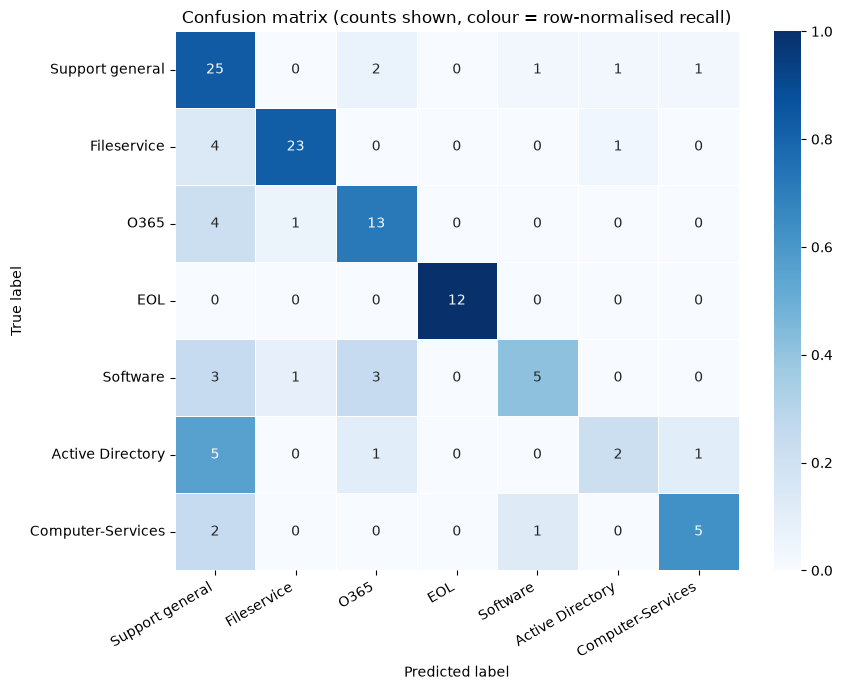


Active Directory recall : 22.2%
Fileservice recall      : 82.1%


In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm      = confusion_matrix(y_true, y_pred, labels=LABEL_TOKENS)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues",
            xticklabels=LABEL_TOKENS, yticklabels=LABEL_TOKENS, linewidths=0.5, ax=ax)
ax.set_title("Confusion matrix (counts shown, colour = row-normalised recall)")
ax.set_ylabel("True label")
ax.set_xlabel("Predicted label")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(NB_OUT / "confusion_matrix.png", dpi=120)
plt.show()

ad_recall   = cm_norm[LABEL_TOKENS.index("Active Directory"), LABEL_TOKENS.index("Active Directory")]
file_recall = cm_norm[LABEL_TOKENS.index("Fileservice"),      LABEL_TOKENS.index("Fileservice")]
print(f"\nActive Directory recall : {ad_recall:.1%}")
print(f"Fileservice recall      : {file_recall:.1%}")
if ad_recall < 0.85:
    print("Warning: Active Directory recall below 0.85 — consider training longer.")

## Baseline vs Fine-tuned Comparison

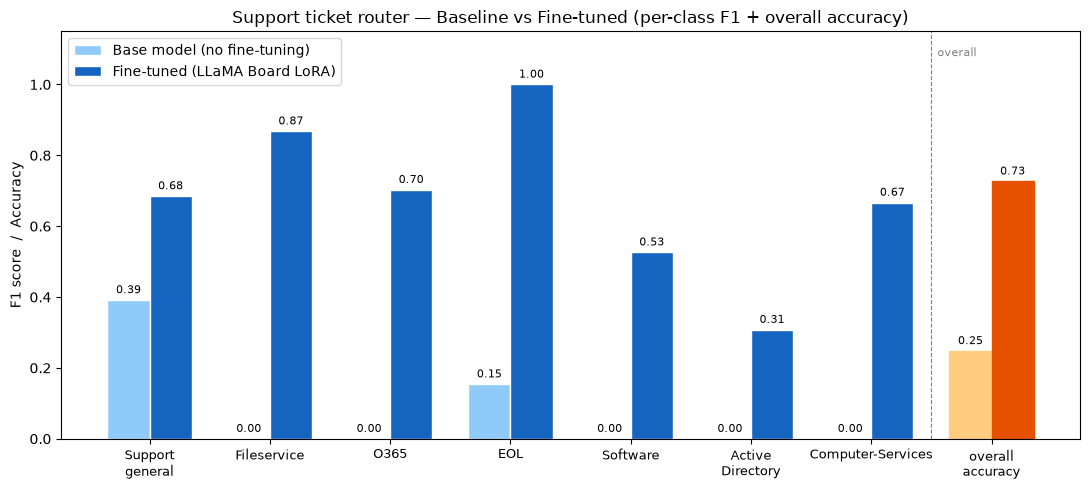


Base accuracy  : 24.8%
Fine-tuned acc : 72.6%
Delta          : +47.9%


In [11]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, accuracy_score


def per_class_f1(y_t, y_p, labels):
    # FIX: labels=labels keeps each F1 score attached to the right class
    report = classification_report(y_t, y_p, labels=labels, target_names=labels, output_dict=True, zero_division=0)
    return {lbl: report[lbl]["f1-score"] for lbl in labels}


ft_f1    = per_class_f1(y_true, y_pred,      LABEL_TOKENS)
base_f1  = per_class_f1(y_true, y_pred_base, LABEL_TOKENS)
ft_acc   = accuracy_score(y_true, y_pred)
base_acc = accuracy_score(y_true, y_pred_base)

labels_plot = LABEL_TOKENS + ["overall accuracy"]
ft_vals     = [ft_f1[l]   for l in LABEL_TOKENS] + [ft_acc]
base_vals   = [base_f1[l] for l in LABEL_TOKENS] + [base_acc]

x, width = np.arange(len(labels_plot)), 0.35
fig, ax = plt.subplots(figsize=(11, 5))
bars_base = ax.bar(x - width/2, base_vals, width, label="Base model (no fine-tuning)", color="#90CAF9", edgecolor="white")
bars_ft   = ax.bar(x + width/2, ft_vals,   width, label="Fine-tuned (LLaMA Board LoRA)", color="#1565C0", edgecolor="white")
ax.bar_label(bars_base, fmt="{:.2f}", padding=3, fontsize=8)
ax.bar_label(bars_ft,   fmt="{:.2f}", padding=3, fontsize=8)
bars_base[-1].set_color("#FFCC80")
bars_ft[-1].set_color("#E65100")
ax.set_ylim(0, 1.15)
ax.set_xticks(x)
ax.set_xticklabels([l.replace(" ", "\n") for l in labels_plot], fontsize=9)
ax.set_ylabel("F1 score  /  Accuracy")
ax.set_title("Support ticket router — Baseline vs Fine-tuned (per-class F1 + overall accuracy)")
ax.legend()
ax.axvline(len(LABEL_TOKENS) - 0.5, color="grey", linestyle="--", linewidth=0.8)
ax.text(len(LABEL_TOKENS) - 0.5 + 0.05, 1.08, "overall", fontsize=8, color="grey")
plt.tight_layout()
plt.savefig(NB_OUT / "baseline_vs_finetuned.png", dpi=120)
plt.show()

print(f"\nBase accuracy  : {base_acc:.1%}")
print(f"Fine-tuned acc : {ft_acc:.1%}")
print(f"Delta          : +{(ft_acc - base_acc):.1%}")

## Where to go from here

The full analysis, with polished charts, context baselines (TF-IDF + logistic regression), baseline
sensitivity, confidence thresholds, latency and error analysis, is in
[`docs/PHASE6_EVALUATION.md`](../docs/PHASE6_EVALUATION.md) and the [README](../README.md).